In [1]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.4.5


In [2]:
import duckdb

# Create DuckDB connection
con = duckdb.connect()

# Load S3 support
con.execute("LOAD httpfs;")

# Configure AWS region
con.execute("SET s3_region = 'us-east-2';")

print("DuckDB:", duckdb.__version__)
print("S3 extension: Loaded")
print("AWS region: us-east-2")
print("Ethereum analytics environment ready!")

DuckDB: 1.4.5
S3 extension: Loaded
AWS region: us-east-2
Ethereum analytics environment ready!


In [3]:
url = "https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date=2026-10-28/part-00000-cc47f3aa-ac0b-41f2-91b4-9b144e7cf1a9-c000.snappy.parquet"

result = con.execute(f"""
    SELECT
        block_number,
        transaction_index,
        from_address,
        to_address,
        receipt_status
    FROM read_parquet('{url}')
    LIMIT 5
""").df()

result

,block_number,transaction_index,from_address,to_address,receipt_status
0,26287496,0,0x2252f216f4a494a87025123425181ca1bb754fb8,0x0000000aa232009084bd71a5797d089aa4edfad4,1
1,26287496,1,0x46187698198fa02f071d999347fe0db2ee79934b,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
2,26287496,2,0x8316174a0f13c9aae7f2409a19ebd8ec8c69aaf4,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
3,26287496,3,0x81dc771e308c76c3e06f635abed7fb24830fb824,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1
4,26287496,4,0xd2700e7bbe0a8af6d6c5b3f61d27855daa425a53,0x51c72848c68a965f66fa7a88855f9f7784502a7f,1


In [4]:
schema = con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_parquet('{url}')
""").df()

schema

,column_name,column_type,null,key,default,extra
0,gas,BIGINT,YES,None,None,None
1,hash,VARCHAR,YES,None,None,None
2,input,VARCHAR,YES,None,None,None
3,nonce,BIGINT,YES,None,None,None
4,value,DOUBLE,YES,None,None,None
5,block_number,BIGINT,YES,None,None,None
6,block_hash,VARCHAR,YES,None,None,None
7,transaction_index,BIGINT,YES,None,None,None
8,from_address,VARCHAR,YES,None,None,None
9,to_address,VARCHAR,YES,None,None,None


In [5]:
summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 1
        ) AS successful_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE receipt_status = 1
            ) / COUNT(*), 2
        ) AS success_rate_pct
    FROM read_parquet('{url}')
""").df()

summary

,total_transactions,successful_transactions,failed_transactions,success_rate_pct
0,1996106,1971694,24412,98.78


In [6]:
hourly = con.execute(f"""
    SELECT
        EXTRACT(HOUR FROM block_timestamp) AS hour,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions
    FROM read_parquet('{url}')
    GROUP BY hour
    ORDER BY hour
""").df()

hourly

IOException: IO Error: SSL connection failed error for HTTP HEAD to 'https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date=2026-10-28/part-00000-cc47f3aa-ac0b-41f2-91b4-9b144e7cf1a9-c000.snappy.parquet'

LINE 8:     FROM read_parquet('https://aws-public-blockchain.s3.us-east-2...
                 ^

In [7]:
test = con.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{url}')
    LIMIT 1
""").fetchone()

print(test)

(1996106,)


In [8]:
hourly = con.execute(f"""
    SELECT
        EXTRACT(HOUR FROM block_timestamp) AS hour,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions
    FROM read_parquet('{url}')
    GROUP BY hour
    ORDER BY hour
""").df()

hourly

,hour,total_transactions,failed_transactions
0,0,139247,1837
1,1,94675,1055
2,2,68581,1750
3,3,63719,1179
4,4,62349,930
5,5,57211,807
6,6,58863,679
7,7,83311,798
8,8,73797,914
9,9,132144,830


In [9]:
hourly["failure_rate_pct"] = (
    hourly["failed_transactions"]
    / hourly["total_transactions"]
    * 100
).round(2)

hourly

,hour,total_transactions,failed_transactions,failure_rate_pct
0,0,139247,1837,1.32
1,1,94675,1055,1.11
2,2,68581,1750,2.55
3,3,63719,1179,1.85
4,4,62349,930,1.49
5,5,57211,807,1.41
6,6,58863,679,1.15
7,7,83311,798,0.96
8,8,73797,914,1.24
9,9,132144,830,0.63


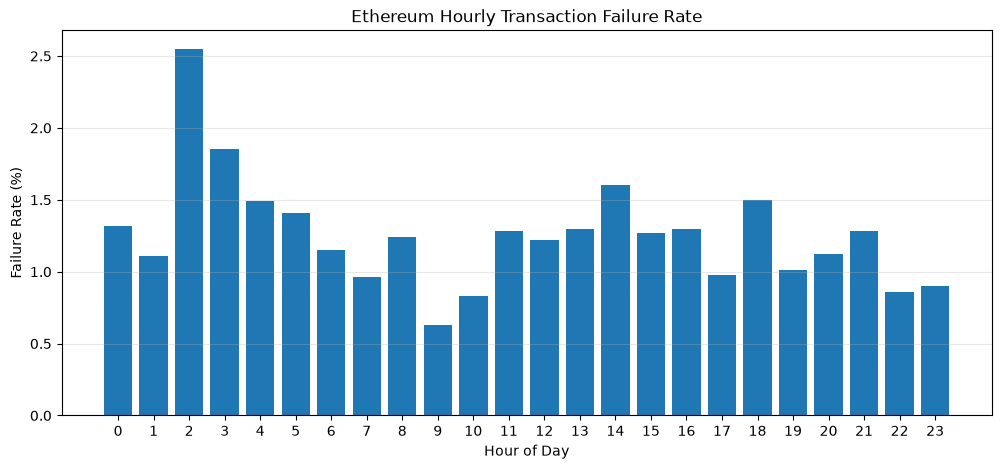

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    hourly["hour"],
    hourly["failure_rate_pct"]
)

plt.title("Ethereum Hourly Transaction Failure Rate")
plt.xlabel("Hour of Day")
plt.ylabel("Failure Rate (%)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()

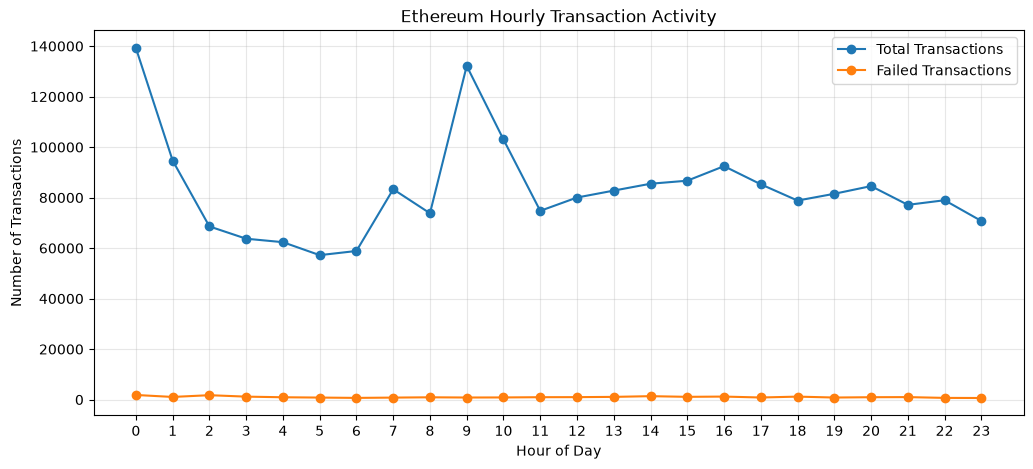

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly["hour"],
    hourly["total_transactions"],
    marker="o",
    label="Total Transactions"
)

plt.plot(
    hourly["hour"],
    hourly["failed_transactions"],
    marker="o",
    label="Failed Transactions"
)

plt.title("Ethereum Hourly Transaction Activity")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [12]:
tx_types = con.execute(f"""
    SELECT
        transaction_type,
        COUNT(*) AS total_transactions,
        COUNT(*) FILTER (
            WHERE receipt_status = 0
        ) AS failed_transactions,
        ROUND(
            100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
            2
        ) AS transaction_share_pct
    FROM read_parquet('{url}')
    GROUP BY transaction_type
    ORDER BY transaction_type
""").df()

tx_types

,transaction_type,total_transactions,failed_transactions,transaction_share_pct
0,0,424874,4855,21.29
1,1,495,5,0.02
2,2,1528571,18925,76.58
3,3,16498,0,0.83
4,4,25668,627,1.29


In [13]:
tx_types["failure_rate_pct"] = (
    tx_types["failed_transactions"]
    / tx_types["total_transactions"]
    * 100
).round(2)

tx_types

,transaction_type,total_transactions,failed_transactions,transaction_share_pct,failure_rate_pct
0,0,424874,4855,21.29,1.14
1,1,495,5,0.02,1.01
2,2,1528571,18925,76.58,1.24
3,3,16498,0,0.83,0.00
4,4,25668,627,1.29,2.44


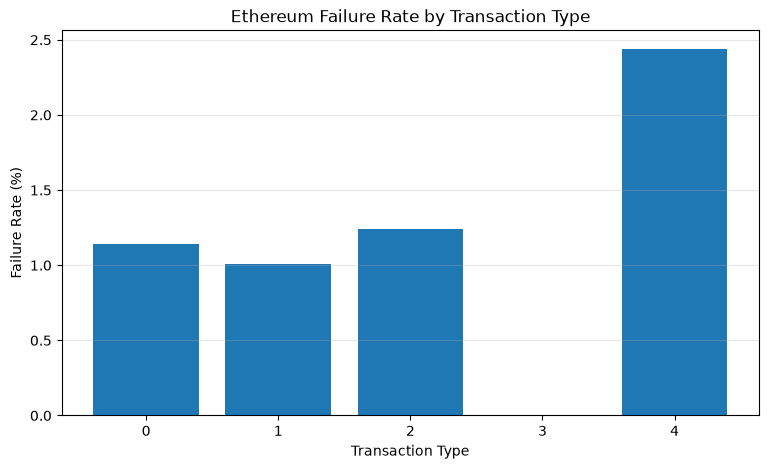

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    tx_types["transaction_type"].astype(str),
    tx_types["failure_rate_pct"]
)

plt.title("Ethereum Failure Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Failure Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

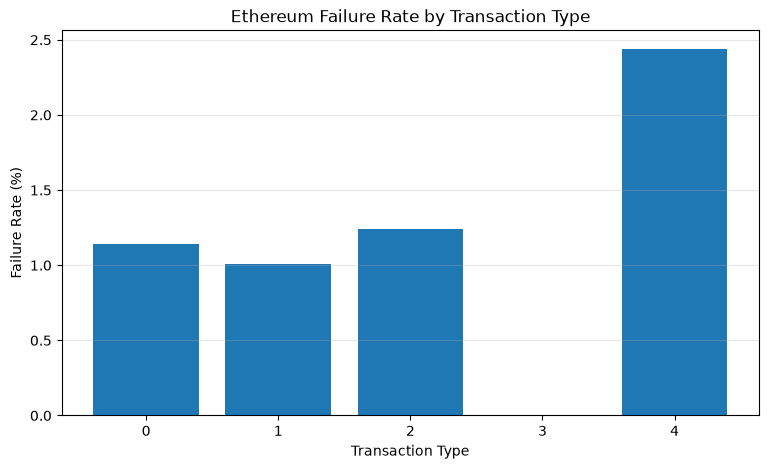

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(
    tx_types["transaction_type"].astype(str),
    tx_types["failure_rate_pct"]
)

plt.title("Ethereum Failure Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Failure Rate (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [17]:
gas_analysis = con.execute(f"""
    SELECT
        CASE
            WHEN receipt_status = 1 THEN 'Successful'
            WHEN receipt_status = 0 THEN 'Failed'
            ELSE 'Unknown'
        END AS transaction_status,
        COUNT(*) AS total_transactions,
        ROUND(AVG(receipt_gas_used), 2) AS avg_gas_used,
        ROUND(AVG(receipt_effective_gas_price) / 1e9, 4)
            AS avg_gas_price_gwei,
        ROUND(
            SUM(
                receipt_gas_used * receipt_effective_gas_price
            ) / 1e18,
            4
        ) AS estimated_fees_eth
    FROM read_parquet('{url}')
    GROUP BY transaction_status
    ORDER BY transaction_status
""").df()

gas_analysis

,transaction_status,total_transactions,avg_gas_used,avg_gas_price_gwei,estimated_fees_eth
0,Failed,24412,144501.51,0.4794,1.2745
1,Successful,1971694,108875.65,0.6166,109.1463


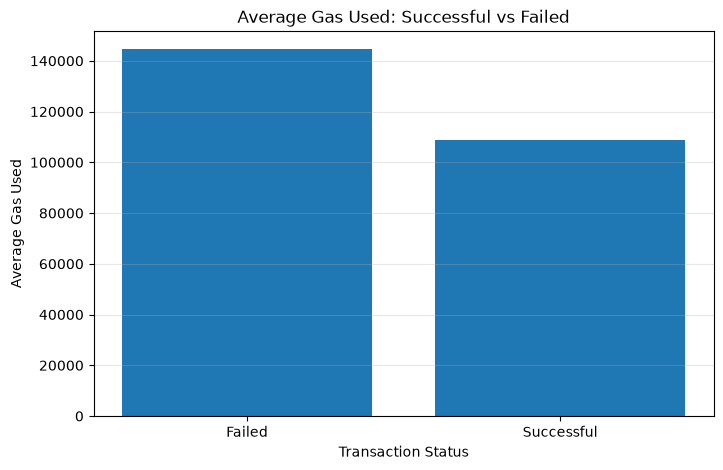

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    gas_analysis["transaction_status"],
    gas_analysis["avg_gas_used"]
)

plt.title("Average Gas Used: Successful vs Failed")
plt.xlabel("Transaction Status")
plt.ylabel("Average Gas Used")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [19]:
total_fees = gas_analysis["estimated_fees_eth"].sum()

total_transactions = gas_analysis["total_transactions"].sum()

average_fee = total_fees / total_transactions

print(f"Total estimated fees: {total_fees:.4f} ETH")
print(f"Total transactions: {total_transactions:,}")
print(f"Average fee: {average_fee:.10f} ETH")

Total estimated fees: 110.4208 ETH
Total transactions: 1,996,106
Average fee: 0.0000553181 ETH


In [20]:
hourly.to_csv("ethereum_hourly_analysis.csv", index=False)

tx_types.to_csv("ethereum_transaction_types.csv", index=False)

gas_analysis.to_csv("ethereum_gas_analysis.csv", index=False)

print("Three analysis files saved successfully.")

Three analysis files saved successfully.


In [21]:
import os

files = [
    "ethereum_hourly_analysis.csv",
    "ethereum_transaction_types.csv",
    "ethereum_gas_analysis.csv"
]

for file in files:
    print(file, "—", os.path.getsize(file), "bytes")

ethereum_hourly_analysis.csv — 515 bytes
ethereum_transaction_types.csv — 212 bytes
ethereum_gas_analysis.csv — 174 bytes


In [22]:
import os

print(os.getcwd())

C:\Users\AL MUZDAHAR COMPUTER\DataScience\Ethereum_OnChain_Analytics
